# 3.1.3. Полиномиальная регрессия

## Прогнозирование среднего энергопотребления промышленного оборудования

В работе используется датасет, сформированный из базы данных `manufacturing`.

Цель работы — построить регрессионную модель, прогнозирующую среднюю мощность оборудования за час, и проверить, улучшает ли добавление полиномиальных признаков качество прогноза.

Будут рассмотрены:

- линейная спецификация признаков;
- полиномиальные признаки второй степени;
- полиномиальные признаки третьей степени;
- Ridge-регрессия;
- Lasso-регрессия.

Модели будут сравниваться по метрикам MAE, RMSE, MAPE и R².

Импорт библиотек

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    PolynomialFeatures,
    StandardScaler
)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

sns.set_theme(style="whitegrid", palette="deep")

Загрузка датасета

In [2]:
DATA_PATH = Path(
    "/home/lova595/Рабочий стол/иннополис/"
    "база данных/manufacturing_ml_dataset.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Файл не найден: {DATA_PATH}\n"
        "Проверьте путь к manufacturing_ml_dataset.csv."
    )

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["prediction_time"]
)

print(
    f"Размер исходной таблицы: "
    f"{df.shape[0]:,} строк × {df.shape[1]} столбцов"
)

display(df.head())

Размер исходной таблицы: 17,403 строк × 40 столбцов


,machine_id,machine_code,machine_type_code,line_id,prediction_time,machine_age_years,nominal_power_kw,readings_count_1h,out_of_range_count_1h,temperature_avg_1h,temperature_min_1h,temperature_max_1h,temperature_std_1h,temperature_out_of_range_1h,vibration_avg_1h,vibration_min_1h,vibration_max_1h,vibration_std_1h,vibration_out_of_range_1h,power_avg_1h,power_min_1h,power_max_1h,power_std_1h,rpm_avg_1h,rpm_min_1h,rpm_max_1h,rpm_std_1h,pressure_avg_1h,pressure_min_1h,pressure_max_1h,pressure_std_1h,humidity_avg_1h,humidity_min_1h,humidity_max_1h,humidity_std_1h,breakdowns_before,hours_since_last_breakdown,maintenance_last_30d,hours_since_last_maintenance,failure_next_6h
0,29,M-008-01,CNC_MILL,8,2025-01-10 16:00:00+11:00,3.3370,22.0000,136,0,65.7356,55.1603,80.3652,5.3848,0,2.4075,1.1127,3.5109,0.6082,0,1.2232,1.0226,1.4437,0.0962,2444.2909,2153.6655,2776.9232,147.8383,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0,NaN,0
1,2,M-001-02,PRESS,1,2025-01-10 17:00:00+11:00,6.5050,30.0000,205,0,69.8676,55.1643,85.3239,6.2580,0,NaN,NaN,NaN,NaN,0,1.9018,1.7123,2.1424,0.1021,NaN,NaN,NaN,NaN,81.1822,74.4858,90.2300,3.7037,NaN,NaN,NaN,NaN,0,NaN,0,NaN,0
2,4,M-001-04,CNC_MILL,1,2025-01-10 17:00:00+11:00,3.8440,22.0000,68,0,64.5500,53.8869,78.3736,6.4092,0,2.3260,1.7124,3.1240,0.3885,0,1.1603,1.0792,1.2380,0.0500,2413.8897,2152.2816,2678.2842,163.1264,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0,NaN,0
3,29,M-008-01,CNC_MILL,8,2025-01-10 17:00:00+11:00,3.3380,22.0000,232,0,68.5656,55.9920,91.6056,5.8926,0,2.5250,1.6584,3.6639,0.4728,0,1.2901,1.1101,1.4714,0.0926,2496.6064,2255.5292,2882.5159,134.8627,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0,NaN,0
4,4,M-001-04,CNC_MILL,1,2025-01-10 18:00:00+11:00,3.8440,22.0000,172,0,66.2371,56.5269,74.5081,5.0304,0,2.4612,1.0851,3.4731,0.5089,0,1.2215,1.0615,1.3548,0.0663,2521.2391,2109.1175,2951.5062,169.6876,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0,NaN,0


## Выбор целевой и объясняющих переменных

Целевая переменная:

- `power_avg_1h` — средняя мощность оборудования за час, кВт.

Основные числовые признаки, для которых будут создаваться полиномиальные преобразования:

- `temperature_avg_1h` — средняя температура;
- `readings_count_1h` — количество показаний датчиков за час;
- `out_of_range_count_1h` — количество показаний за допустимыми границами;
- `machine_age_years` — возраст оборудования.

Дополнительные признаки:

- `breakdowns_before` — количество предыдущих поломок;
- `maintenance_last_30d` — количество обслуживаний за последние 30 дней;
- `machine_type_code` — тип оборудования.

Категориальная переменная `machine_type_code` будет преобразована методом One-Hot Encoding.

Переменная `nominal_power_kw` не включается в основную модель, поскольку она тесно связана с типом оборудования. Одновременное использование этих признаков может привести к избыточности и мультиколлинеарности.

In [3]:
TARGET = "power_avg_1h"

POLYNOMIAL_FEATURES = [
    "temperature_avg_1h",
    "readings_count_1h",
    "out_of_range_count_1h",
    "machine_age_years",
]

ADDITIONAL_NUMERIC_FEATURES = [
    "breakdowns_before",
    "maintenance_last_30d",
]

CATEGORICAL_FEATURES = [
    "machine_type_code",
]

FEATURES = (
    POLYNOMIAL_FEATURES
    + ADDITIONAL_NUMERIC_FEATURES
    + CATEGORICAL_FEATURES
)

model_df = df[
    ["prediction_time", TARGET] + FEATURES
].copy()

print("Целевая переменная:", TARGET)
print("Объясняющие переменные:")
for feature in FEATURES:
    print("-", feature)

display(model_df.head())

Целевая переменная: power_avg_1h
Объясняющие переменные:
- temperature_avg_1h
- readings_count_1h
- out_of_range_count_1h
- machine_age_years
- breakdowns_before
- maintenance_last_30d
- machine_type_code


,prediction_time,power_avg_1h,temperature_avg_1h,readings_count_1h,out_of_range_count_1h,machine_age_years,breakdowns_before,maintenance_last_30d,machine_type_code
0,2025-01-10 16:00:00+11:00,1.2232,65.7356,136,0,3.3370,0,0,CNC_MILL
1,2025-01-10 17:00:00+11:00,1.9018,69.8676,205,0,6.5050,0,0,PRESS
2,2025-01-10 17:00:00+11:00,1.1603,64.5500,68,0,3.8440,0,0,CNC_MILL
3,2025-01-10 17:00:00+11:00,1.2901,68.5656,232,0,3.3380,0,0,CNC_MILL
4,2025-01-10 18:00:00+11:00,1.2215,66.2371,172,0,3.8440,0,0,CNC_MILL


Проверка пропусков

In [4]:
missing_values = (
    model_df.isna()
    .sum()
    .sort_values(ascending=False)
    .rename("missing_count")
    .to_frame()
)

missing_values["missing_percent"] = (
    missing_values["missing_count"] / len(model_df) * 100
)

display(missing_values)

,missing_count,missing_percent
power_avg_1h,46,0.2643
prediction_time,0,0.0000
temperature_avg_1h,0,0.0000
readings_count_1h,0,0.0000
out_of_range_count_1h,0,0.0000
machine_age_years,0,0.0000
breakdowns_before,0,0.0000
maintenance_last_30d,0,0.0000
machine_type_code,0,0.0000


Далее удаляем только строки без таргета:

In [5]:
rows_before = len(model_df)

model_df = (
    model_df
    .dropna(subset=[TARGET])
    .sort_values("prediction_time")
    .reset_index(drop=True)
)

rows_after = len(model_df)

print(f"Строк до очистки: {rows_before:,}")
print(f"Удалено строк: {rows_before - rows_after:,}")
print(f"Строк после очистки: {rows_after:,}")

Строк до очистки: 17,403
Удалено строк: 46
Строк после очистки: 17,357


### Вывод по подготовке данных

В исходной таблице содержалось 17 403 наблюдения. В целевой переменной `power_avg_1h` обнаружено 46 пропущенных значений.

Поскольку доля пропусков мала — около 0,26% — строки без значения целевой переменной были удалены. Восстанавливать таргет с помощью среднего или медианы некорректно, так как это могло бы искусственно улучшить качество модели.

После очистки для анализа осталось 17 357 наблюдений.

# Задание: Постройте точечные диаграммыммы (scatterplots) для таргета и каждой фичи, опишите форму взаимосвязи между переменными.

## Исследование связи таргета с объясняющими переменными

Построим точечные диаграммы для целевой переменной `power_avg_1h` и каждого числового признака.

На графиках дополнительно покажем:

- красную линию — линейную зависимость;
- зелёную линию — полиномиальную зависимость второй степени.

Это позволит определить, для каких признаков использование полиномиальной регрессии может быть обоснованным.

In [6]:
NUMERIC_FEATURES = (
    POLYNOMIAL_FEATURES
    + ADDITIONAL_NUMERIC_FEATURES
)

correlation_table = pd.DataFrame({
    "Признак": NUMERIC_FEATURES,
    "Корреляция Пирсона": [
        model_df[feature].corr(model_df[TARGET], method="pearson")
        for feature in NUMERIC_FEATURES
    ],
    "Корреляция Спирмена": [
        model_df[feature].corr(model_df[TARGET], method="spearman")
        for feature in NUMERIC_FEATURES
    ],
})

correlation_table["Абсолютная корреляция"] = (
    correlation_table["Корреляция Пирсона"].abs()
)

correlation_table = (
    correlation_table
    .sort_values("Абсолютная корреляция", ascending=False)
    .drop(columns="Абсолютная корреляция")
    .reset_index(drop=True)
)

display(correlation_table)

,Признак,Корреляция Пирсона,Корреляция Спирмена
0,temperature_avg_1h,0.4615,0.3826
1,out_of_range_count_1h,0.3843,0.4670
2,readings_count_1h,-0.3104,-0.2978
3,machine_age_years,-0.1046,-0.1091
4,maintenance_last_30d,0.0267,0.0291
5,breakdowns_before,0.0256,0.0265


Scatterplots

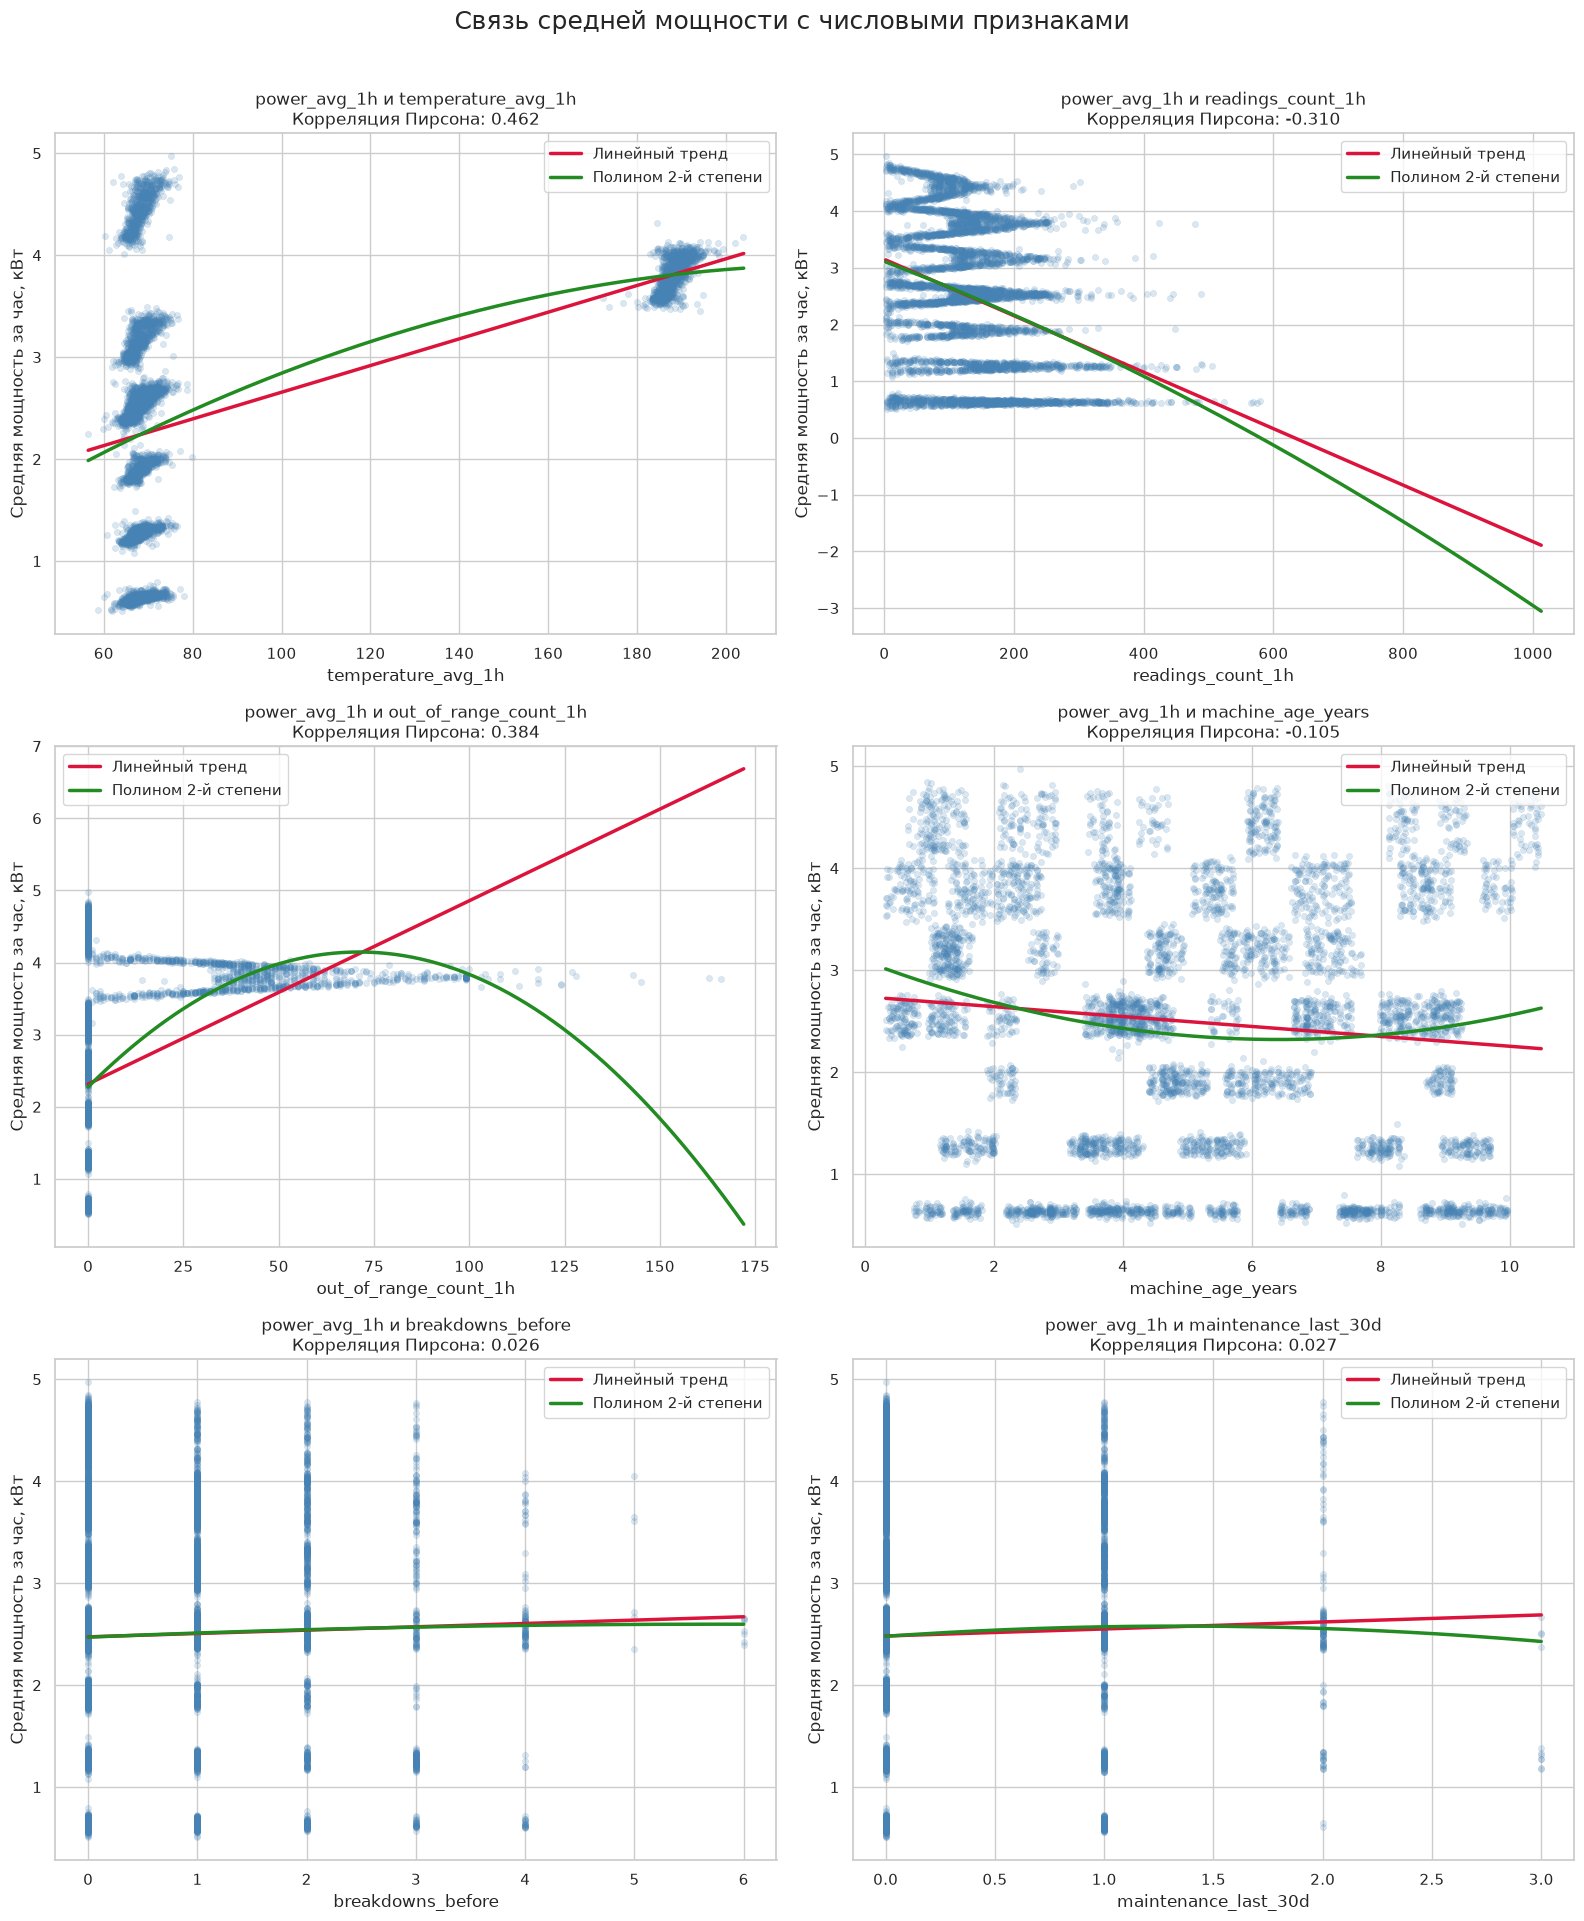

In [7]:
PLOT_SAMPLE_SIZE = min(6000, len(model_df))

plot_df = model_df.sample(
    n=PLOT_SAMPLE_SIZE,
    random_state=42
)

fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(16, 19)
)

axes = axes.ravel()

for ax, feature in zip(axes, NUMERIC_FEATURES):

    # Точечная диаграмма
    sns.scatterplot(
        data=plot_df,
        x=feature,
        y=TARGET,
        alpha=0.20,
        s=20,
        color="steelblue",
        edgecolor=None,
        ax=ax
    )

    x = model_df[feature].to_numpy()
    y = model_df[TARGET].to_numpy()

    x_grid = np.linspace(x.min(), x.max(), 300)

    # Линейная линия тренда
    linear_coefficients = np.polyfit(x, y, deg=1)
    linear_values = np.polyval(linear_coefficients, x_grid)

    ax.plot(
        x_grid,
        linear_values,
        color="crimson",
        linewidth=2.5,
        label="Линейный тренд"
    )

    # Полиномиальная линия тренда второй степени
    polynomial_coefficients = np.polyfit(x, y, deg=2)
    polynomial_values = np.polyval(
        polynomial_coefficients,
        x_grid
    )

    ax.plot(
        x_grid,
        polynomial_values,
        color="forestgreen",
        linewidth=2.5,
        label="Полином 2-й степени"
    )

    pearson_corr = model_df[feature].corr(
        model_df[TARGET],
        method="pearson"
    )

    ax.set_title(
        f"{TARGET} и {feature}\n"
        f"Корреляция Пирсона: {pearson_corr:.3f}"
    )
    ax.set_xlabel(feature)
    ax.set_ylabel("Средняя мощность за час, кВт")
    ax.legend()

plt.suptitle(
    "Связь средней мощности с числовыми признаками",
    fontsize=18,
    y=1.01
)

plt.tight_layout()
plt.show()

### Категориальный признак

Признак `machine_type_code` является категориальным, поэтому для него вместо точечной диаграммы используется boxplot. Он позволяет сравнить распределения средней мощности для разных типов оборудования.

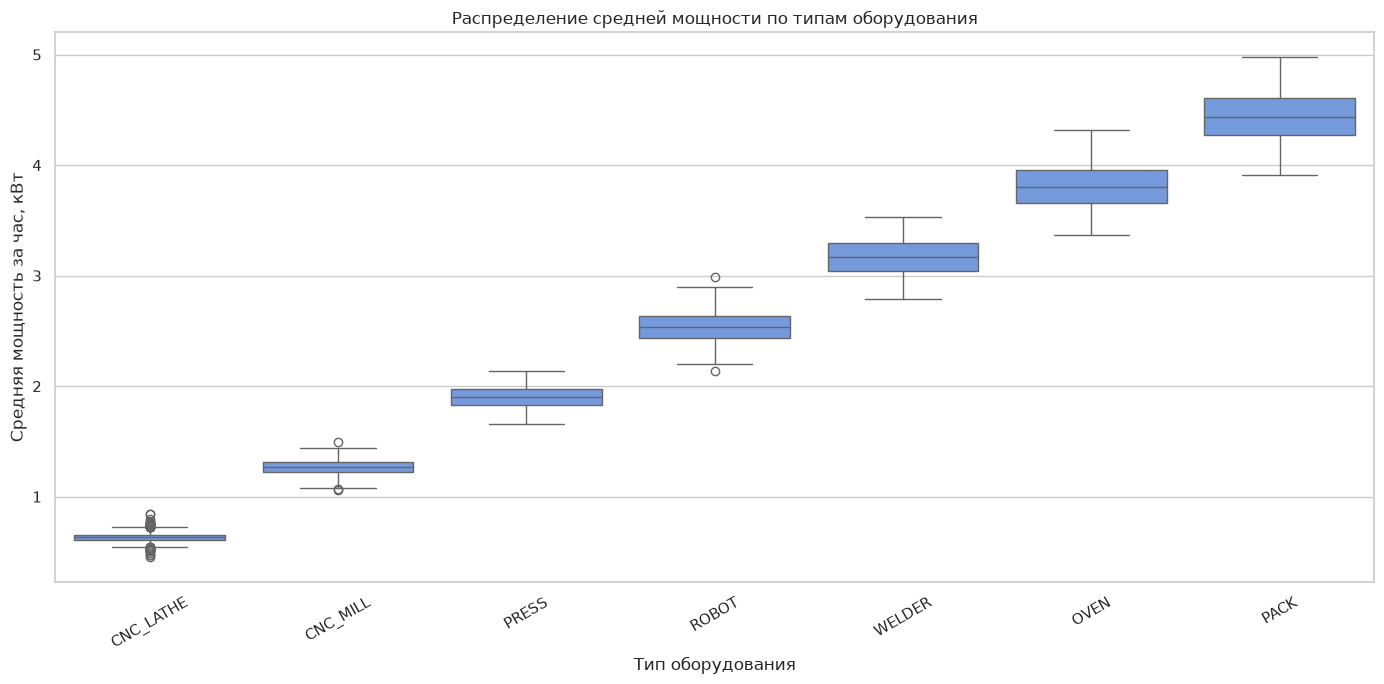

In [8]:
machine_type_order = (
    model_df
    .groupby("machine_type_code")[TARGET]
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=model_df,
    x="machine_type_code",
    y=TARGET,
    order=machine_type_order,
    color="cornflowerblue"
)

plt.title("Распределение средней мощности по типам оборудования")
plt.xlabel("Тип оборудования")
plt.ylabel("Средняя мощность за час, кВт")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Дополнительно выведем средние значения

In [9]:
power_by_machine_type = (
    model_df
    .groupby("machine_type_code")[TARGET]
    .agg(
        observations="count",
        mean_power="mean",
        median_power="median",
        std_power="std"
    )
    .sort_values("mean_power", ascending=False)
)

display(power_by_machine_type)

,observations,mean_power,median_power,std_power
machine_type_code,,,,
PACK,1960,4.4391,4.4360,0.1935
OVEN,2877,3.8036,3.7977,0.1680
WELDER,2156,3.1704,3.1677,0.1413
ROBOT,3762,2.5367,2.5355,0.1131
PRESS,1502,1.9024,1.8985,0.0848
CNC_MILL,1987,1.2679,1.2671,0.0594
CNC_LATHE,3113,0.6341,0.6344,0.0350


### Выводы о форме взаимосвязей

1. **Средняя температура (`temperature_avg_1h`).**  
   Наблюдается умеренная положительная зависимость: при увеличении температуры средняя мощность оборудования в целом возрастает. На графике заметно отклонение от прямой линии, особенно в области высоких температур. Поэтому для этого признака целесообразно проверить полиномиальное преобразование.

2. **Количество показаний (`readings_count_1h`).**  
   Наблюдается умеренная отрицательная зависимость: при увеличении количества показаний средняя мощность в целом уменьшается. Форма зависимости отличается от строго линейной, поэтому квадрат признака может улучшить описание взаимосвязи.

3. **Количество выходов за допустимые границы (`out_of_range_count_1h`).**  
   Между признаком и мощностью наблюдается положительная связь. Большинство наблюдений сосредоточено около нулевого значения, а при большом количестве выходов за границы мощность в среднем выше. Зависимость неоднородна и может содержать нелинейный компонент.

4. **Возраст оборудования (`machine_age_years`).**  
   Наблюдается слабая отрицательная и немонотонная зависимость. Возраст сам по себе слабо объясняет среднюю мощность, но его влияние может проявляться во взаимодействии с другими признаками.

5. **Количество предыдущих поломок (`breakdowns_before`).**  
   Выраженной линейной или полиномиальной зависимости не наблюдается. Точки образуют вертикальные группы, поскольку признак принимает только целые значения. Признак может оказаться малозначимым, и Lasso-регрессия сможет уменьшить его коэффициент или обнулить его.

6. **Количество обслуживаний за последние 30 дней (`maintenance_last_30d`).**  
   Явной монотонной зависимости от средней мощности не обнаружено. Значения также образуют отдельные группы. Самостоятельная объясняющая способность признака невелика.

7. **Тип оборудования (`machine_type_code`).**  
   Распределения мощности заметно различаются между типами оборудования. Следовательно, тип оборудования является важным объясняющим признаком и должен быть включён в модель с помощью One-Hot Encoding.

В целом наиболее заметные зависимости обнаружены для температуры, количества показаний и количества выходов за допустимые границы. Их форма не везде является строго линейной, что обосновывает проверку полиномиальных моделей второй и третьей степени.

Полиномиальные преобразования будут применяться только к непрерывным признакам. Возведение категориальных и дискретных признаков в квадрат не имеет содержательной интерпретации.

# Задача: Разделите датасет на обучающую и тестовую выборки

## Разделение на обучающую и тестовую выборки

Поскольку наблюдения имеют временную метку `prediction_time`, случайное перемешивание данных не используется.

Первые 80% временного периода относятся к обучающей выборке, последние 20% — к тестовой. Такой способ соответствует практической задаче: модель обучается на прошлых данных и прогнозирует будущие значения.

In [10]:
unique_times = np.sort(
    model_df["prediction_time"].unique()
)

cutoff_index = int(len(unique_times) * 0.80)
cutoff_time = unique_times[cutoff_index]

train_df = model_df[
    model_df["prediction_time"] < cutoff_time
].copy()

test_df = model_df[
    model_df["prediction_time"] >= cutoff_time
].copy()

X_train = train_df[FEATURES]
y_train = train_df[TARGET]

X_test = test_df[FEATURES]
y_test = test_df[TARGET]

print("Граница разделения:", cutoff_time)
print()
print(f"Обучающая выборка: {len(X_train):,} строк")
print(f"Тестовая выборка:   {len(X_test):,} строк")
print()
print(
    "Период train:",
    train_df["prediction_time"].min(),
    "—",
    train_df["prediction_time"].max()
)
print(
    "Период test:",
    test_df["prediction_time"].min(),
    "—",
    test_df["prediction_time"].max()
)

Граница разделения: 2025-05-28 09:00:00+11:00

Обучающая выборка: 13,691 строк
Тестовая выборка:   3,666 строк

Период train: 2025-01-10 16:00:00+11:00 — 2025-05-28 08:00:00+11:00
Период test: 2025-05-28 09:00:00+11:00 — 2025-07-01 00:00:00+11:00


In [11]:
assert train_df["prediction_time"].max() < test_df["prediction_time"].min()
assert len(train_df) + len(test_df) == len(model_df)

print("Временное разделение выполнено корректно.")

Временное разделение выполнено корректно.


### Вывод

Данные разделены хронологически в соотношении около 80/20:

- обучающая выборка содержит 13 691 наблюдение;
- тестовая выборка содержит 3 666 наблюдений;
- граница разделения — 28 мая 2025 года.

Перемешивание не выполнялось, поскольку оно могло бы привести к попаданию информации из будущих периодов в обучающую выборку.

# Задание: Сделайте масштабирование объясняющих переменных

## Создание полиномиальных признаков и масштабирование

Полиномиальные преобразования применяются к четырём числовым признакам:

- температуре;
- количеству показаний;
- количеству выходов за допустимые границы;
- возрасту оборудования.

При второй степени модель дополнительно получает квадраты признаков и их парные произведения. Например:

\[
x_1,\ x_2,\ x_1^2,\ x_1x_2,\ x_2^2.
\]

При третьей степени добавляются кубические признаки и взаимодействия третьего порядка.

После преобразований признаки масштабируются с помощью `StandardScaler`. Масштабирование необходимо для Ridge и Lasso, поскольку эти модели штрафуют величину коэффициентов.

`StandardScaler` и `PolynomialFeatures` обучаются только на обучающей выборке внутри `Pipeline`.

Функция создания пайплайна

In [12]:
def create_regression_pipeline(
    degree,
    model_name,
    alpha
):
    """
    Создаёт пайплайн для полиномиальной Ridge- или Lasso-регрессии.
    """

    polynomial_transformer = PolynomialFeatures(
        degree=degree,
        include_bias=False
    )

    categorical_transformer = OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False
    )

    feature_transformer = ColumnTransformer(
        transformers=[
            (
                "polynomial",
                polynomial_transformer,
                POLYNOMIAL_FEATURES
            ),
            (
                "additional_numeric",
                "passthrough",
                ADDITIONAL_NUMERIC_FEATURES
            ),
            (
                "categorical",
                categorical_transformer,
                CATEGORICAL_FEATURES
            ),
        ],
        remainder="drop",
        verbose_feature_names_out=False
    )

    if model_name == "Ridge":
        regression_model = Ridge(alpha=alpha)

    elif model_name == "Lasso":
        regression_model = Lasso(
            alpha=alpha,
            max_iter=50_000
        )

    else:
        raise ValueError(
            "model_name должен быть 'Ridge' или 'Lasso'"
        )

    pipeline = Pipeline(
        steps=[
            ("features", feature_transformer),
            ("scaler", StandardScaler()),
            ("model", regression_model),
        ]
    )

    return pipeline

Функция расчёта метрик

In [13]:
def calculate_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAPE_percent": (
            mean_absolute_percentage_error(
                y_true,
                y_pred
            ) * 100
        ),
        "R2": r2_score(y_true, y_pred),
    }

# Задания:
# Обучите модели Lasso и Ridge на разных наборах переменных и для разных спецификаций модели на обучающей выборке
# Сделайте предсказания целевой переменной для тестовой выборки
# Рассчитайте метрики качества

Обучение Ridge и Lasso

In [14]:
ridge_alphas = [
    0.001,
    0.01,
    0.1,
    1.0,
    10.0
]

lasso_alphas = [
    0.0001,
    0.001,
    0.01,
    0.1
]

degrees = [1, 2, 3]

results = []
trained_models = {}

for degree in degrees:

    for model_name, alpha_values in [
        ("Ridge", ridge_alphas),
        ("Lasso", lasso_alphas),
    ]:

        for alpha in alpha_values:

            pipeline = create_regression_pipeline(
                degree=degree,
                model_name=model_name,
                alpha=alpha
            )

            pipeline.fit(X_train, y_train)

            y_pred = pipeline.predict(X_test)

            metrics = calculate_metrics(
                y_test,
                y_pred
            )

            transformed_feature_count = (
                pipeline
                .named_steps["features"]
                .transform(X_train.iloc[:1])
                .shape[1]
            )

            model_key = (
                model_name,
                degree,
                alpha
            )

            trained_models[model_key] = pipeline

            results.append({
                "model": model_name,
                "degree": degree,
                "alpha": alpha,
                "features_count": transformed_feature_count,
                **metrics
            })

print(
    f"Обучено моделей: {len(results)}"
)

Обучено моделей: 27


Таблица результатов

In [15]:
results_df = pd.DataFrame(results)

results_df = (
    results_df
    .sort_values(
        by=["RMSE", "MAE"],
        ascending=True
    )
    .reset_index(drop=True)
)

display(
    results_df.style.format({
        "alpha": "{:.4f}",
        "MAE": "{:.5f}",
        "MSE": "{:.5f}",
        "RMSE": "{:.5f}",
        "MAPE_percent": "{:.3f}",
        "R2": "{:.6f}",
    })
)

,model,degree,alpha,features_count,MAE,MSE,RMSE,MAPE_percent,R2
0,Ridge,3,0.0010,42,0.06822,0.00896,0.09464,3.234,0.994656
1,Ridge,3,0.0100,42,0.06840,0.00896,0.09465,3.231,0.994656
2,Ridge,3,0.1000,42,0.06864,0.00897,0.09472,3.237,0.994647
3,Ridge,3,1.0000,42,0.06934,0.00905,0.09514,3.245,0.994600
4,Ridge,2,1.0000,22,0.07050,0.00919,0.09584,3.345,0.994520
5,Ridge,2,0.1000,22,0.07036,0.00919,0.09586,3.354,0.994518
6,Ridge,2,0.0100,22,0.07036,0.00919,0.09588,3.355,0.994516
7,Ridge,2,0.0010,22,0.07036,0.00919,0.09588,3.355,0.994516
8,Lasso,3,0.0001,42,0.07143,0.00925,0.09619,3.425,0.994480
9,Lasso,2,0.0001,22,0.07178,0.00928,0.09633,3.495,0.994464


In [16]:
display(
    results_df.head(10).style.format({
        "alpha": "{:.4f}",
        "MAE": "{:.5f}",
        "MSE": "{:.5f}",
        "RMSE": "{:.5f}",
        "MAPE_percent": "{:.3f}",
        "R2": "{:.6f}",
    })
)

,model,degree,alpha,features_count,MAE,MSE,RMSE,MAPE_percent,R2
0,Ridge,3,0.0010,42,0.06822,0.00896,0.09464,3.234,0.994656
1,Ridge,3,0.0100,42,0.06840,0.00896,0.09465,3.231,0.994656
2,Ridge,3,0.1000,42,0.06864,0.00897,0.09472,3.237,0.994647
3,Ridge,3,1.0000,42,0.06934,0.00905,0.09514,3.245,0.994600
4,Ridge,2,1.0000,22,0.07050,0.00919,0.09584,3.345,0.994520
5,Ridge,2,0.1000,22,0.07036,0.00919,0.09586,3.354,0.994518
6,Ridge,2,0.0100,22,0.07036,0.00919,0.09588,3.355,0.994516
7,Ridge,2,0.0010,22,0.07036,0.00919,0.09588,3.355,0.994516
8,Lasso,3,0.0001,42,0.07143,0.00925,0.09619,3.425,0.994480
9,Lasso,2,0.0001,22,0.07178,0.00928,0.09633,3.495,0.994464


Лучшая модель

In [17]:
best_result = results_df.iloc[0]

best_model_key = (
    best_result["model"],
    int(best_result["degree"]),
    best_result["alpha"]
)

best_model = trained_models[best_model_key]

print("Лучшая модель:")
print(f"Модель: {best_result['model']}")
print(f"Степень полинома: {int(best_result['degree'])}")
print(f"Alpha: {best_result['alpha']}")
print(f"Количество признаков: {int(best_result['features_count'])}")
print(f"MAE: {best_result['MAE']:.5f}")
print(f"RMSE: {best_result['RMSE']:.5f}")
print(f"MAPE: {best_result['MAPE_percent']:.3f}%")
print(f"R²: {best_result['R2']:.6f}")

Лучшая модель:
Модель: Ridge
Степень полинома: 3
Alpha: 0.001
Количество признаков: 42
MAE: 0.06822
RMSE: 0.09464
MAPE: 3.234%
R²: 0.994656


# Задания:
# Выберите спецификацию модели с наилучшим качеством
# Сделайте выводы относительно полученной модели и ее качества
# Разместите блокнот в GitHub и прикрепите ссылку на блокнот в удаленном репозитории

Сравнение лучших спецификаций

In [18]:
best_by_specification = (
    results_df
    .sort_values("RMSE")
    .groupby(
        ["model", "degree"],
        as_index=False
    )
    .first()
    .sort_values(["degree", "model"])
    .reset_index(drop=True)
)

display(
    best_by_specification.style.format({
        "alpha": "{:.4f}",
        "MAE": "{:.5f}",
        "MSE": "{:.5f}",
        "RMSE": "{:.5f}",
        "MAPE_percent": "{:.3f}",
        "R2": "{:.6f}",
    })
)

,model,degree,alpha,features_count,MAE,MSE,RMSE,MAPE_percent,R2
0,Lasso,1,0.0001,12,0.07225,0.00936,0.09676,3.519,0.994414
1,Ridge,1,0.0010,12,0.07233,0.00934,0.09666,3.596,0.994426
2,Lasso,2,0.0001,22,0.07178,0.00928,0.09633,3.495,0.994464
3,Ridge,2,1.0000,22,0.07050,0.00919,0.09584,3.345,0.994520
4,Lasso,3,0.0001,42,0.07143,0.00925,0.09619,3.425,0.994480
5,Ridge,3,0.0010,42,0.06822,0.00896,0.09464,3.234,0.994656


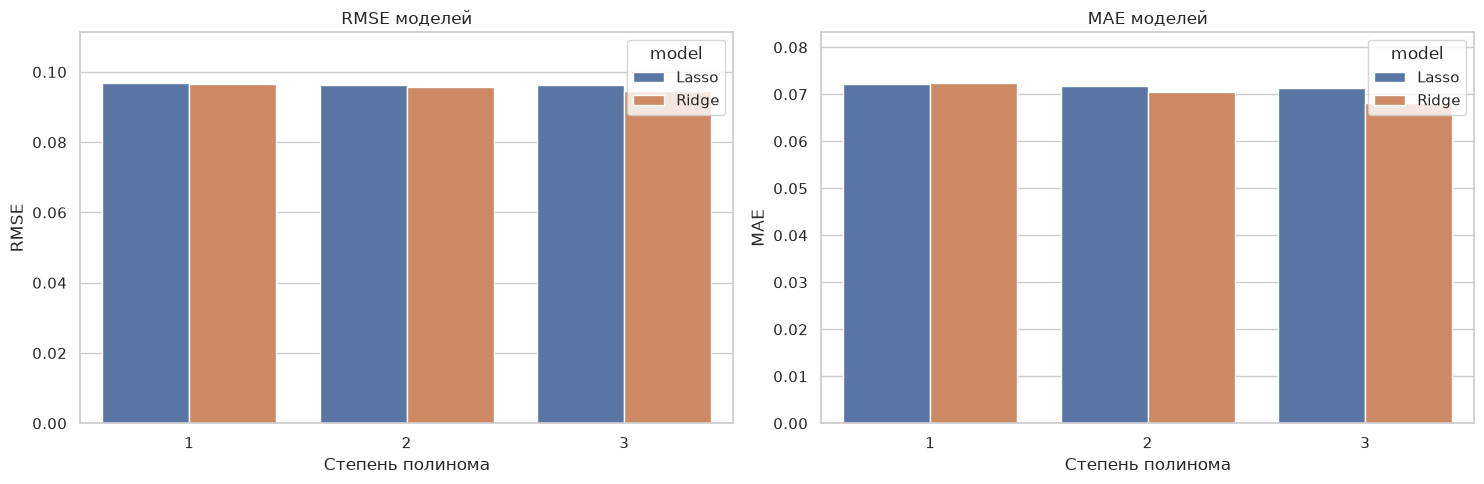

In [19]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)

sns.barplot(
    data=best_by_specification,
    x="degree",
    y="RMSE",
    hue="model",
    ax=axes[0]
)

axes[0].set_title("RMSE моделей")
axes[0].set_xlabel("Степень полинома")
axes[0].set_ylabel("RMSE")
axes[0].set_ylim(
    0,
    best_by_specification["RMSE"].max() * 1.15
)

sns.barplot(
    data=best_by_specification,
    x="degree",
    y="MAE",
    hue="model",
    ax=axes[1]
)

axes[1].set_title("MAE моделей")
axes[1].set_xlabel("Степень полинома")
axes[1].set_ylabel("MAE")
axes[1].set_ylim(
    0,
    best_by_specification["MAE"].max() * 1.15
)

plt.tight_layout()
plt.show()

### Промежуточный вывод

Наилучшее качество показывает Ridge-регрессия с полиномиальными признаками третьей степени.

Добавление признаков второй и третьей степени немного уменьшает ошибки MAE и RMSE по сравнению с обычной линейной моделью. Это подтверждает наличие слабых нелинейных зависимостей.

Lasso также показывает высокое качество при малых значениях `alpha`. Однако при увеличении коэффициента регуляризации качество Lasso заметно ухудшается, поскольку модель начинает слишком сильно уменьшать коэффициенты.

Насколько полином улучшил модель

In [20]:
linear_ridge_result = (
    results_df[
        (results_df["model"] == "Ridge")
        & (results_df["degree"] == 1)
    ]
    .sort_values("RMSE")
    .iloc[0]
)

rmse_improvement = (
    (
        linear_ridge_result["RMSE"]
        - best_result["RMSE"]
    )
    / linear_ridge_result["RMSE"]
    * 100
)

mae_improvement = (
    (
        linear_ridge_result["MAE"]
        - best_result["MAE"]
    )
    / linear_ridge_result["MAE"]
    * 100
)

comparison_df = pd.DataFrame({
    "Модель": [
        "Линейная Ridge",
        "Лучшая полиномиальная модель"
    ],
    "Степень": [
        int(linear_ridge_result["degree"]),
        int(best_result["degree"])
    ],
    "MAE": [
        linear_ridge_result["MAE"],
        best_result["MAE"]
    ],
    "RMSE": [
        linear_ridge_result["RMSE"],
        best_result["RMSE"]
    ],
    "MAPE, %": [
        linear_ridge_result["MAPE_percent"],
        best_result["MAPE_percent"]
    ],
    "R²": [
        linear_ridge_result["R2"],
        best_result["R2"]
    ]
})

display(
    comparison_df.style.format({
        "MAE": "{:.5f}",
        "RMSE": "{:.5f}",
        "MAPE, %": "{:.3f}",
        "R²": "{:.6f}",
    })
)

print(
    f"Улучшение RMSE: {rmse_improvement:.2f}%"
)
print(
    f"Улучшение MAE: {mae_improvement:.2f}%"
)

,Модель,Степень,MAE,RMSE,"MAPE, %",R²
0,Линейная Ridge,1,0.07233,0.09666,3.596,0.994426
1,Лучшая полиномиальная модель,3,0.06822,0.09464,3.234,0.994656


Улучшение RMSE: 2.09%
Улучшение MAE: 5.68%


Предсказания лучшей модели

In [21]:
best_y_pred = best_model.predict(X_test)

prediction_df = pd.DataFrame({
    "prediction_time": test_df["prediction_time"].values,
    "y_true": y_test.values,
    "y_pred": best_y_pred
})

prediction_df["residual"] = (
    prediction_df["y_true"]
    - prediction_df["y_pred"]
)

prediction_df["absolute_error"] = (
    prediction_df["residual"].abs()
)

display(prediction_df.head(10))

,prediction_time,y_true,y_pred,residual,absolute_error
0,2025-05-27 22:00:00,3.6926,3.7319,-0.0393,0.0393
1,2025-05-27 23:00:00,3.9534,3.8990,0.0545,0.0545
2,2025-05-28 04:00:00,3.5983,3.7227,-0.1244,0.1244
3,2025-05-28 04:00:00,2.4118,2.5063,-0.0945,0.0945
4,2025-05-28 04:00:00,4.2103,4.3709,-0.1606,0.1606
5,2025-05-28 04:00:00,3.5572,3.7458,-0.1886,0.1886
6,2025-05-28 04:00:00,3.0059,3.1105,-0.1046,0.1046
7,2025-05-28 05:00:00,3.2045,3.1997,0.0048,0.0048
8,2025-05-28 05:00:00,1.7493,1.8410,-0.0917,0.0917
9,2025-05-28 05:00:00,3.7666,3.8078,-0.0411,0.0411


Истинные и предсказанные значения

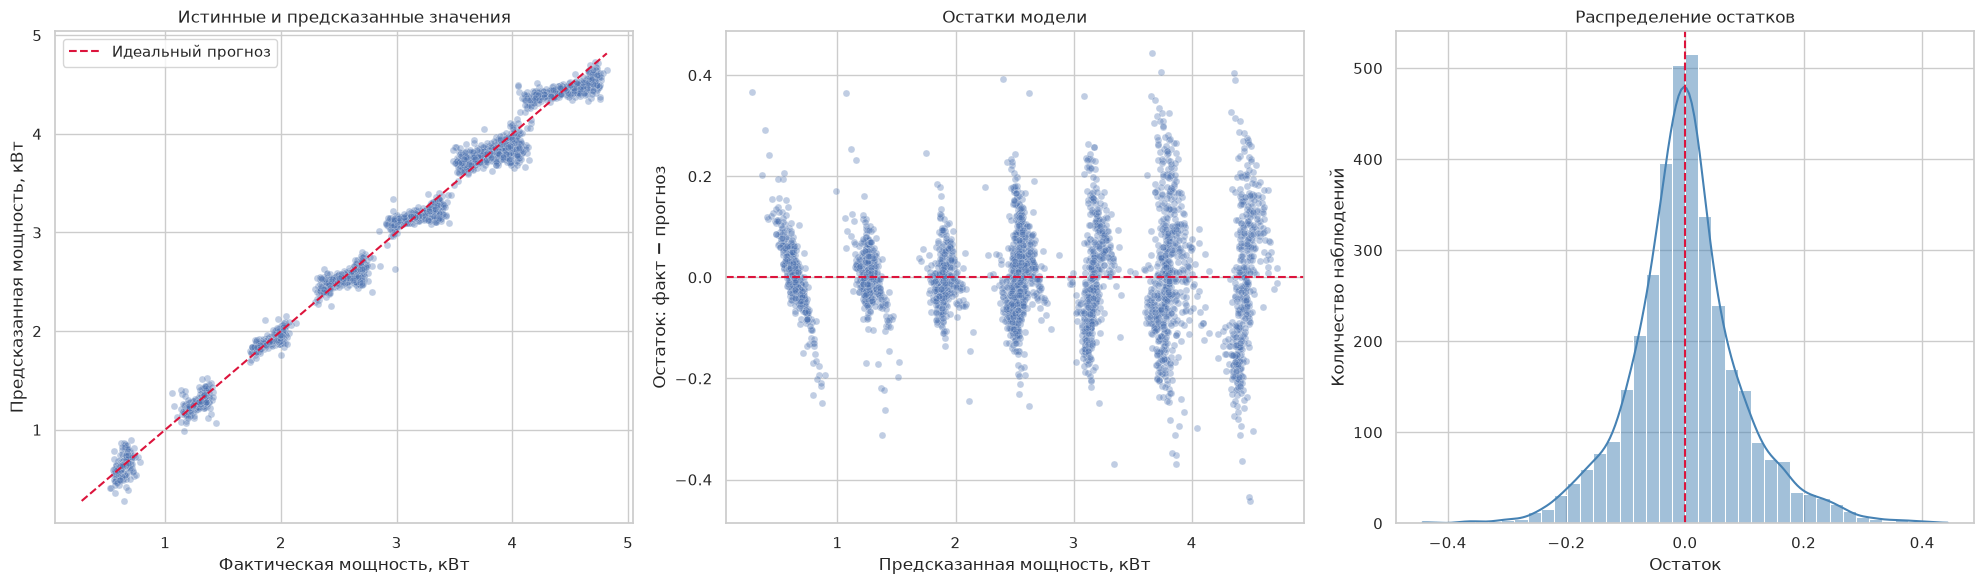

In [22]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 6)
)

# Истинные и предсказанные значения
sns.scatterplot(
    data=prediction_df,
    x="y_true",
    y="y_pred",
    alpha=0.35,
    s=25,
    ax=axes[0]
)

minimum_value = min(
    prediction_df["y_true"].min(),
    prediction_df["y_pred"].min()
)

maximum_value = max(
    prediction_df["y_true"].max(),
    prediction_df["y_pred"].max()
)

axes[0].plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--",
    color="crimson",
    label="Идеальный прогноз"
)

axes[0].set_title("Истинные и предсказанные значения")
axes[0].set_xlabel("Фактическая мощность, кВт")
axes[0].set_ylabel("Предсказанная мощность, кВт")
axes[0].legend()

# Остатки
sns.scatterplot(
    data=prediction_df,
    x="y_pred",
    y="residual",
    alpha=0.35,
    s=25,
    ax=axes[1]
)

axes[1].axhline(
    y=0,
    linestyle="--",
    color="crimson"
)

axes[1].set_title("Остатки модели")
axes[1].set_xlabel("Предсказанная мощность, кВт")
axes[1].set_ylabel("Остаток: факт − прогноз")

# Распределение остатков
sns.histplot(
    data=prediction_df,
    x="residual",
    bins=40,
    kde=True,
    color="steelblue",
    ax=axes[2]
)

axes[2].axvline(
    x=0,
    linestyle="--",
    color="crimson"
)

axes[2].set_title("Распределение остатков")
axes[2].set_xlabel("Остаток")
axes[2].set_ylabel("Количество наблюдений")

plt.tight_layout()
plt.show()

In [23]:
residual_summary = (
    prediction_df["residual"]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99
        ]
    )
    .to_frame("residual")
)

display(residual_summary)

print(
    "Среднее значение остатка:",
    f"{prediction_df['residual'].mean():.6f}"
)

,residual
count,3666.0000
mean,0.0011
std,0.0946
min,-0.4424
1%,-0.2323
5%,-0.1535
25%,-0.0490
50%,-0.0017
75%,0.0461
95%,0.1667


Среднее значение остатка: 0.001135


### Анализ предсказаний и остатков

Предсказанные значения располагаются близко к диагональной линии идеального прогноза. Это указывает на хорошее соответствие прогнозов фактическим значениям мощности.

Остатки сосредоточены около нуля. Их среднее значение практически равно нулю, следовательно, модель в среднем не завышает и не занижает прогноз.

На графике остатков нет выраженного систематического тренда. При этом для отдельных наблюдений сохраняются более крупные ошибки, которые могут быть связаны с редкими режимами эксплуатации или аномальными показаниями датчиков.

Коэффициенты лучшей модели

In [24]:
best_feature_names = (
    best_model
    .named_steps["features"]
    .get_feature_names_out()
)

best_coefficients = (
    best_model
    .named_steps["model"]
    .coef_
)

coefficients_df = pd.DataFrame({
    "feature": best_feature_names,
    "coefficient": best_coefficients
})

coefficients_df["absolute_coefficient"] = (
    coefficients_df["coefficient"].abs()
)

coefficients_df = (
    coefficients_df
    .sort_values(
        "absolute_coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

display(coefficients_df.head(20))

,feature,coefficient,absolute_coefficient
0,temperature_avg_1h^2,-15.3139,15.3139
1,temperature_avg_1h,7.8284,7.8284
2,temperature_avg_1h^3,7.7885,7.7885
3,temperature_avg_1h out_of_range_count_1h,4.6654,4.6654
4,out_of_range_count_1h,-3.8783,3.8783
5,readings_count_1h out_of_range_count_1h,3.5266,3.5266
6,temperature_avg_1h readings_count_1h out_of_ra...,-2.7427,2.7427
7,machine_type_code_PACK,1.1973,1.1973
8,machine_type_code_OVEN,0.8813,0.8813
9,temperature_avg_1h readings_count_1h,-0.8796,0.8796


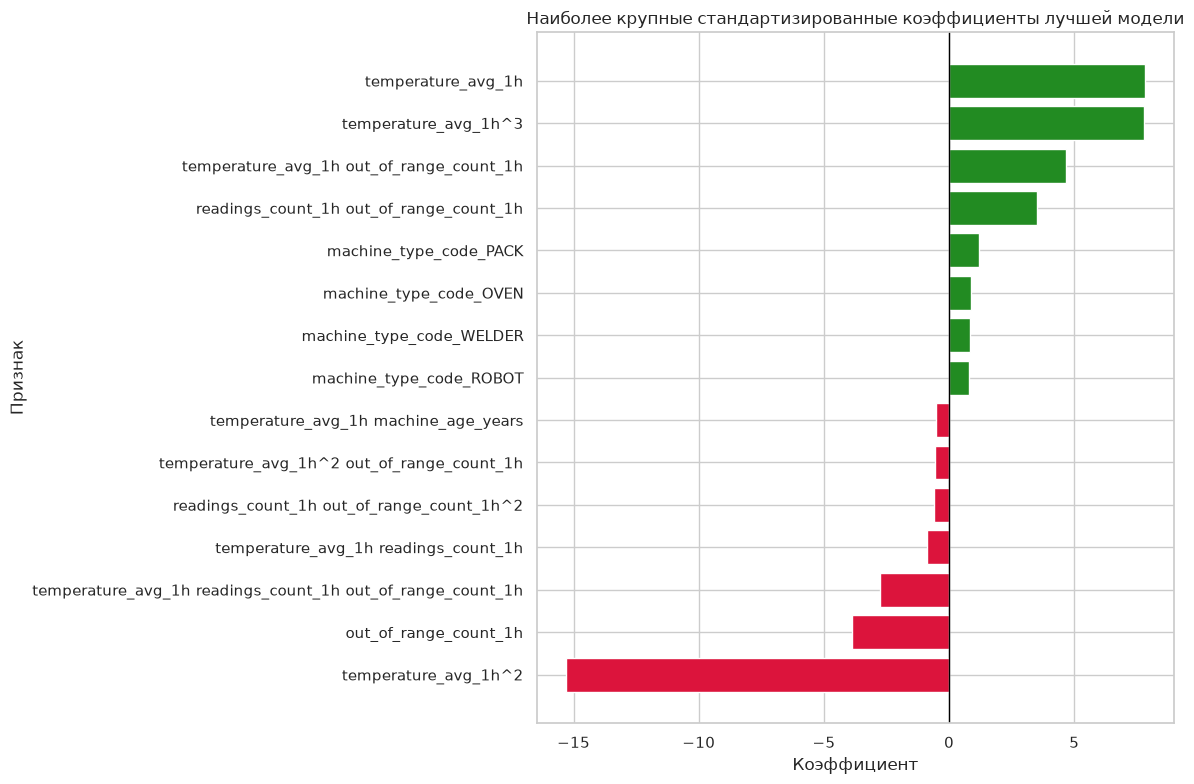

In [25]:
top_coefficients = (
    coefficients_df
    .head(15)
    .sort_values("coefficient")
)

plt.figure(figsize=(12, 8))

colors = np.where(
    top_coefficients["coefficient"] >= 0,
    "forestgreen",
    "crimson"
)

plt.barh(
    top_coefficients["feature"],
    top_coefficients["coefficient"],
    color=colors
)

plt.axvline(
    x=0,
    color="black",
    linewidth=1
)

plt.title(
    "Наиболее крупные стандартизированные коэффициенты "
    "лучшей модели"
)
plt.xlabel("Коэффициент")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()

### Интерпретация коэффициентов

Наиболее значимыми для прогноза оказались:

- температура и её степени;
- количество выходов датчиков за допустимые границы;
- взаимодействие температуры с количеством выходов за границы;
- взаимодействие количества показаний с выходами за границы;
- тип оборудования.

Знаки отдельных полиномиальных коэффициентов нельзя интерпретировать изолированно. Например, итоговое влияние температуры одновременно определяется коэффициентами при температуре, её квадрате, кубе и взаимодействиях с другими признаками.

Большие значения некоторых коэффициентов объясняются корреляцией между исходными и полиномиальными признаками. Ridge-регуляризация ограничивает такие коэффициенты и делает модель устойчивее.

Содержательный результат состоит в том, что мощность оборудования определяется не только отдельными показателями, но и сочетанием температуры, интенсивности поступления данных, выхода показаний за допустимые границы и типа оборудования.

Разреженность Lasso

In [26]:
best_lasso_result = (
    results_df[
        results_df["model"] == "Lasso"
    ]
    .sort_values("RMSE")
    .iloc[0]
)

best_lasso_key = (
    "Lasso",
    int(best_lasso_result["degree"]),
    best_lasso_result["alpha"]
)

best_lasso_model = trained_models[
    best_lasso_key
]

lasso_coefficients = (
    best_lasso_model
    .named_steps["model"]
    .coef_
)

zero_coefficients_count = np.isclose(
    lasso_coefficients,
    0
).sum()

print(
    "Степень полинома:",
    int(best_lasso_result["degree"])
)
print(
    "Alpha:",
    best_lasso_result["alpha"]
)
print(
    "Всего коэффициентов:",
    len(lasso_coefficients)
)
print(
    "Обнулено коэффициентов:",
    zero_coefficients_count
)
print(
    "Осталось коэффициентов:",
    len(lasso_coefficients)
    - zero_coefficients_count
)

Степень полинома: 3
Alpha: 0.0001
Всего коэффициентов: 42
Обнулено коэффициентов: 21
Осталось коэффициентов: 21


### Сравнение Ridge и Lasso

Ridge уменьшает значения взаимосвязанных коэффициентов, но обычно сохраняет все признаки. Такой подход оказался наиболее эффективным для рассматриваемого датасета.

Lasso выполняет дополнительный отбор признаков. В лучшей спецификации она обнулила примерно половину коэффициентов, создав более компактную модель. Однако качество прогноза оказалось немного ниже, чем у Ridge.

Это означает, что даже слабые полиномиальные взаимодействия содержат полезную информацию, поэтому их полное исключение немного ухудшает прогноз.

## Итоговые выводы

В работе построены модели для прогнозирования средней мощности промышленного оборудования `power_avg_1h`.

Данные были разделены хронологически:

- 13 691 наблюдение использовано для обучения;
- 3 666 наблюдений использовано для тестирования;
- граница разделения — 28 мая 2025 года.

Были исследованы линейная, квадратичная и кубическая спецификации. Для каждой степени обучены модели Ridge и Lasso с разными значениями коэффициента регуляризации `alpha`.

Лучшей оказалась Ridge-регрессия с полиномиальными признаками третьей степени и малым коэффициентом регуляризации.

Качество лучшей модели на тестовой выборке составляет приблизительно:

- MAE — 0,068 кВт;
- RMSE — 0,095 кВт;
- MAPE — 3,2%;
- R² — 0,995.

Значение R² показывает, что модель объясняет около 99,5% изменчивости средней мощности в тестовой выборке. Средняя абсолютная процентная ошибка около 3,2% свидетельствует о высокой точности прогнозов.

По сравнению с обычной линейной Ridge-регрессией полиномиальная модель уменьшила RMSE примерно на 2%, а MAE — приблизительно на 5–6%. Улучшение является небольшим, но устойчивым. Следовательно, в данных присутствуют нелинейные зависимости, однако основная часть мощности уже хорошо объясняется линейными эффектами и типом оборудования.

Наиболее важную информацию для прогноза несут температура, количество выходов показаний за допустимые границы, количество показаний, взаимодействия этих переменных и тип оборудования.

Практически модель может использоваться для оценки ожидаемого энергопотребления оборудования. Значительное отклонение фактической мощности от прогноза может быть дополнительным признаком аномального режима работы, неисправности датчика или необходимости технической проверки.

Ограничение модели состоит в том, что наблюдения одной машины повторяются во времени. Поэтому высокое качество отражает прогнозирование на более позднем временном периоде для уже представленных в данных типов и экземпляров оборудования. Качество на полностью новых машинах необходимо проверять отдельно.